In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Generalization in Classification

The softmax regression of that section labels about 83% of
the Fashion-MNIST test images correctly. We would like to read that number as the accuracy the model will have on clothing images it has
never seen, and two things stand in the way. First, the 10,000 test images
are a sample: another 10,000 images from the same source would give a
somewhat different accuracy. Second, a high score on data the model has seen
proves little. A sufficiently expressive model can attain perfect training
accuracy by memorizing the label of each training input and returning that
label whenever the same input appears again. Memorization provides no rule
for a new input, on which such a model can only guess.

This raises three questions:

1. How many test examples do we need to give a good estimate of the accuracy
   of our classifiers on the underlying population?
1. What happens if we keep evaluating models on the same test set
   repeatedly?
1. Why should fitting our linear models to the training set fare any better
   than memorizing it?

that section estimated the error of a model on new
data with held-out examples and kept the test set out of model selection.
This section makes both ideas quantitative for classification. The first two
questions have precise answers in terms of the size of the test set and the
number of times we consult it. The third asks for a guarantee that holds
before we see any test data, whatever the distribution of the data. Such
guarantees explain why fitting a linear model differs from memorizing. For
deep networks they are far too loose to be useful, which is why deep
learning relies on test sets, and on the answers to the first two
questions.

In [ ]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

## The Test Set

A test set measures one classifier. We first ask how precise that
measurement is, as a function of the number of test examples.

### Empirical and Population Error

Consider a fixed classifier $f$, without worrying about how it was obtained,
and a *fresh* dataset
$\mathcal{D} = \{(\mathbf{x}^{(i)}, y^{(i)})\}_{i=1}^n$ of examples that
played no part in obtaining $f$. The *empirical error* of $f$ on
$\mathcal{D}$ is the fraction of examples whose label it gets wrong:

$$\epsilon_{\mathcal{D}}(f) = \frac{1}{n}\sum_{i=1}^n \mathbf{1}\left(f(\mathbf{x}^{(i)}) \neq y^{(i)}\right).$$

The *population error* is the probability that $f$ gets the label wrong on a
new example drawn from the distribution $P(X, Y)$ that generates the data:

$$\epsilon(f) = \mathbb{E}_{(\mathbf{x}, y) \sim P}\left[\mathbf{1}\left(f(\mathbf{x}) \neq y\right)\right] = P\left(f(X) \neq Y\right).$$

These are the empirical risk and the risk of
that section for the *0--1 loss*, which charges 1 for
a wrong label and 0 for a correct one. We want $\epsilon(f)$, but since we do
not know $P$, we can compute only $\epsilon_{\mathcal{D}}(f)$.

Each term $\mathbf{1}(f(\mathbf{x}^{(i)}) \neq y^{(i)})$ equals 1 with
probability $\epsilon(f)$ and 0 otherwise, like a coin that comes up heads
with probability $\epsilon(f)$. The test examples are drawn independently,
and $f$ was fixed before they were drawn, so $\epsilon_{\mathcal{D}}(f)$ is
the frequency of heads in $n$ independent tosses of this coin. Two facts
from that section follow. The estimate is unbiased:
$\mathbb{E}[\epsilon_{\mathcal{D}}(f)] = \epsilon(f)$. And the average of $n$
independent draws has a standard error equal to the standard deviation of a
single draw divided by $\sqrt{n}$. A variable that equals 1 with probability
$\epsilon$ and 0 otherwise has variance $\epsilon(1 - \epsilon)$, so the
standard error of $\epsilon_{\mathcal{D}}(f)$ is
$\sqrt{\epsilon(f)(1 - \epsilon(f))/n}$.

For a classifier with population error $0.15$, about that of softmax
regression on Fashion-MNIST, and $n = 10{,}000$ test images, the standard
error is $\sqrt{0.15 \cdot 0.85 / 10{,}000} \approx 0.0036$, about a third of
a percentage point. The product $\epsilon(1 - \epsilon)$ is largest at
$\epsilon = 1/2$, where it equals $1/4$, so the standard error never
exceeds $0.5/\sqrt{n}$, whatever the classifier. Halving it takes four times
as many test examples. More test data does not change the error of the
classifier, only our uncertainty about it.

### Confidence Intervals

A standard error tells us how large deviations typically are, but not how
often a deviation of a given size occurs. The *central limit theorem* fills
this gap: when $n$ is large, the average of $n$ independent draws of a
random variable with finite variance is approximately normally distributed,
with the true mean as its mean and the standard error as its standard
deviation (that section states the theorem precisely). A
normal random variable lies within 1.96 standard deviations of its mean with
probability 0.95. For the test error this gives

$$P\left(|\epsilon_{\mathcal{D}}(f) - \epsilon(f)| \leq 1.96\sqrt{\frac{\epsilon(f)(1 - \epsilon(f))}{n}}\right) \approx 0.95.$$

Turned around, the interval of 1.96 standard errors around
$\epsilon_{\mathcal{D}}(f)$ contains the population error for 95% of test
sets. It is called a 95% *confidence interval*, and we call its half-width
the *radius*; in practice $\epsilon_{\mathcal{D}}(f)$ takes the place of the
unknown $\epsilon(f)$ in the radius. For softmax regression on the 10,000
Fashion-MNIST test images the radius is about
$1.96 \cdot 0.0036 \approx 0.007$: its accuracy is known to within about
0.7 percentage points.

How many test examples give a radius of $0.01$ at 95%, whatever the error of
the classifier? In the worst case $\epsilon = 1/2$ we need
$1.96 \cdot 0.5/\sqrt{n} \leq 0.01$, that is, $n \geq 9{,}604$. Many
benchmark test sets have about 10,000 examples, Fashion-MNIST's among them,
so the accuracy of a single model on them is known to within about one
percentage point. An accuracy reported as 84.37% has more digits than such a
test set supports.

### Finite-Sample Guarantees

The central limit theorem describes the limit of large $n$. At any finite
$n$ the normal distribution only approximates the distribution of
$\epsilon_{\mathcal{D}}(f)$, and the approximation is poor when the classifier
makes few errors, for example when $\epsilon(f) = 0.001$ and $n = 1{,}000$,
so that we expect a single error. Because each term of the empirical error
lies between 0 and 1, an inequality due to @Hoeffding.1963 gives a
bound that holds at every $n$ and for every distribution:

$$
P\left(|\epsilon_{\mathcal{D}}(f) - \epsilon(f)| \geq t\right) \leq 2\exp\left(-2nt^2\right).
$$

The probability that the test error misses the population error by $t$ or
more falls exponentially in $nt^2$
(that section proves the inequality).
Setting the right-hand side
to $\delta = 0.05$ and solving for $t$ gives the 95% *Hoeffding radius*
$\sqrt{\log(2/\delta)/(2n)}$. A radius of $0.01$ then requires
$n \geq \log(40)/(2 \cdot 0.01^2) \approx 18{,}445$ examples, roughly
18,500, about twice the 9,604 of the normal approximation. Hoeffding's bound
is more conservative because it holds at every $n$ and uses only the range of
each term, not its variance.

### Simulated Test Sets

We check both radii by simulation, for a classifier with population error
$\epsilon(f) = 0.15$. For each of several test set sizes $n$ we draw 10,000
test sets. The number of errors on a test set is a sum of $n$ independent
0--1 variables, which has a binomial distribution, so we draw it directly. We
then compare the simulated 95% radius, the deviation
$|\epsilon_{\mathcal{D}}(f) - \epsilon(f)|$ that 95% of the test sets stay
within, with the radius of the normal approximation and with the Hoeffding
radius.

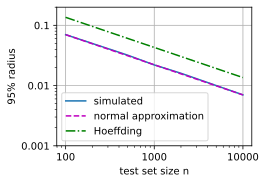

In [2]:
rng = np.random.default_rng()
eps, num_sets = 0.15, 10000
ns = np.array([100, 200, 500, 1000, 2000, 5000, 10000])
# The number of errors on a test set of size n is Binomial(n, eps)
deviations = [np.abs(rng.binomial(n, eps, num_sets) / n - eps) for n in ns]
simulated = [np.quantile(dev, 0.95) for dev in deviations]
normal = 1.96 * np.sqrt(eps * (1 - eps) / ns)
hoeffding = np.sqrt(np.log(2 / 0.05) / (2 * ns))
d2l.plot(ns, [simulated, normal, hoeffding], 'test set size n', '95% radius',
         legend=['simulated', 'normal approximation', 'Hoeffding'],
         xscale='log', yscale='log', ylim=(0.001, 0.2))

On log--log axes the three radii are parallel straight lines of slope
$-1/2$: each shrinks like $1/\sqrt{n}$. The simulated radius lies on the line
of the normal approximation at every test set size, from 100 to 10,000. The
Hoeffding radius lies above both, as a guarantee must, and is about twice as
wide: at $\epsilon = 0.15$ the ratio of the two formulas is $1.94$ for every
$n$. The normal approximation is the better estimate here; Hoeffding's bound
is the one we can rely on without checking whether the approximation holds.

## Test Set Reuse

The guarantees so far concern one classifier, fixed before the test set was
drawn. In practice a test set is consulted again and again: to compare
architectures, to tune hyperparameters, and, for a public benchmark, by every
paper that reports on it. Choosing the best of many classifiers inflates its
score, and when the scores guide the design of the next classifier, the test
set is no longer independent of the classifiers it evaluates.

### Selection Among Many Classifiers

Suppose that we evaluate $k$ classifiers $f_1, \ldots, f_k$, all fixed
before the test set is drawn, and report the one with the lowest test error.
On its own, each test error lies within the Hoeffding radius with probability
0.95. The probability that at least one of them misses by more grows with
$k$, and the classifier with the lowest test error is likely to be one whose
error was underestimated. To guarantee all $k$ estimates at once, we use the
*union bound*: the probability that at least one of several events occurs is
at most the sum of their probabilities. We apply it to the $k$ events "the
test error of $f_j$ misses by $t$ or more", each of which has probability at
most $2\exp(-2nt^2)$ by the equation:

$$
P\left(\max_{j=1,\ldots,k} |\epsilon_{\mathcal{D}}(f_j) - \epsilon(f_j)| \geq t\right) \leq 2k\exp\left(-2nt^2\right).
$$

Setting the right-hand side to $\delta$ shows that, with probability at least
$1 - \delta$, all $k$ test errors lie within $\sqrt{\log(2k/\delta)/(2n)}$ of
their population errors simultaneously. The radius grows only with the
logarithm of $k$. On $10{,}000$ test examples at $\delta = 0.05$ it grows from
$0.014$ for one classifier to $0.023$ for a thousand and $0.030$ for a
million.

To see the selection effect at work, we take the purest case: a test set of
$n = 1{,}000$ examples whose binary labels are coin flips, and $k = 10{,}000$
classifiers that ignore their inputs and guess each label by a coin flip of
their own. Every classifier has population accuracy 0.5, and no classifier can do
better, because the labels carry no information about the inputs. We plot the
best test accuracy among the first $k$ classifiers as $k$ grows, together
with the curve $0.5 + \sqrt{\log(k)/(2n)}$. Each of the two directions of
the deviation in the equation has
probability at most $\exp(-2nt^2)$, so the best of $k$ accuracies exceeds
$0.5 + t$ with probability at most $k\exp(-2nt^2)$, which equals 1 on the
curve and falls quickly above it.

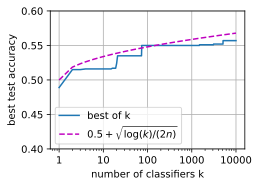

In [3]:
n, k = 1000, 10000
labels = rng.random(n) < 0.5            # one test set with coin-flip labels
guesses = rng.random((k, n)) < 0.5      # k classifiers that guess at random
accuracy = (guesses == labels).mean(axis=1)
ks = np.arange(1, k + 1)
d2l.plot(ks, [np.maximum.accumulate(accuracy),
              0.5 + np.sqrt(np.log(ks) / (2 * n))],
         'number of classifiers k', 'best test accuracy',
         legend=['best of k', r'$0.5 + \sqrt{\log(k) / (2n)}$'], xscale='log',
         ylim=(0.4, 0.6))

The best test accuracy climbs to about 0.56 after 10,000 classifiers and
stays close to the curve, mostly just below it. No classifier learned
anything; the climb comes from selection alone. Whenever we keep the best of
many models by their score on one test set, part of its apparent advantage is
of this kind, and the union bound says how large that part can be.

### Adaptive Overfitting

The union bound requires the $k$ classifiers to be fixed before the test set
is drawn. Model development rarely works that way: we train a model, look at
its test score, and let the score guide the next model. Each new model then
depends on the test set, and the bound no longer applies. The test score of
a model chosen with the help of earlier scores on the same test set can
overestimate its population accuracy far more than selection alone does.
This is called *adaptive overfitting* [@Dwork.Feldman.Hardt.ea.2015].

A simple strategy shows how large the effect can be, using nothing but test
scores [@Blum.Hardt.2015]. We take the first 1,000 random guessers from
above and keep those whose test accuracy exceeds 0.5. A new classifier then
predicts, for each test input, the label that the majority of the kept
guessers predict. On a new input, the kept guessers still flip coins, so their
majority vote is again a coin flip, with population accuracy 0.5.

In [4]:
kept = guesses[:1000][accuracy[:1000] > 0.5]  # guessers that scored above 0.5
vote = kept.mean(axis=0) > 0.5                # their majority vote
print(f'majority vote: {(vote == labels).mean():.3f}, '
      f'best single guesser: {accuracy[:1000].max():.3f}')

majority vote: 0.700, best single guesser: 0.550


The majority vote scores about 0.7 on the test set, far above the best of the
1,000 guessers it combines (between 0.54 and 0.57) and the best of all 10,000
(about 0.56). It never saw a label. Each test score revealed a little about which
guesses agree with the labels, and the vote added up this information over a
thousand scores. Exercise
3 takes the idea to
its end: about $n$ well-chosen scores reveal every label of the test set.

The remedy is the division of labor of that section:
a validation set absorbs model selection and the tuning of hyperparameters,
and the test set is consulted once, for the final model. Public benchmarks
are reused anyway. When @Recht.Roelofs.Schmidt.ea.2019 collected new
test sets for CIFAR-10 and ImageNet following the original procedures,
accuracies dropped by 3 to 15 percentage points, but the models largely kept
their ranking, and slight differences between the old and the new images
explained the drops better than years of adaptive reuse. The worst case is
therefore rare for large benchmarks, but real for small test sets that are
queried often, such as the public leaderboards of competitions.

## Statistical Learning Theory

A test set certifies a classifier after training. It does not explain why
training should produce a classifier that generalizes, and it cannot tell us
in advance how much training data a model needs. Statistical learning theory
answers these questions by reasoning about the training error, which is an
optimistic estimate because training chose the classifier to make it small.
From the point of view of the training set, the learner is a modeler who
evaluated every classifier it could choose on the same data and kept the
best: selection among many classifiers, taken to the extreme.

### Uniform Convergence

Let $\mathcal{F}$ be the set of classifiers the learner can choose from,
called its *hypothesis class*. For binary linear classification with labels
$\pm 1$ it is the set of all classifiers
$f(\mathbf{x}) = \operatorname{sign}(\mathbf{w}^\top \mathbf{x} + b)$. Let
$\mathcal{S}$ be a training set of $n$ examples, $\epsilon_{\mathcal{S}}(f)$
the empirical error of $f$ on it, and $f_{\mathcal{S}}$ the classifier that the
learner picks. If $\mathcal{F}$ is finite, the union bound
the equation applies with
$k = |\mathcal{F}|$ and the training set in place of the test set, because
the class was fixed before the training data were drawn. With probability at
least $1 - \delta$,

$$
|\epsilon_{\mathcal{S}}(f) - \epsilon(f)| \leq \sqrt{\frac{\log(2|\mathcal{F}|/\delta)}{2n}} \quad \textrm{for every } f \in \mathcal{F}.
$$

Because the bound holds for every member of the class at once, it holds in
particular for $f_{\mathcal{S}}$, whichever classifier the learner picks. A
guarantee of this kind is called *uniform convergence*. It makes the training
error a trustworthy estimate of the population error once $n$ is large
compared with $\log|\mathcal{F}|$.

The bound does not yet apply to linear classifiers. Their weights and bias
are real numbers, so $\mathcal{F}$ is infinite, and so is the right-hand side.
Memorization shows that some property of the class must enter any such
guarantee. A memorizer has training error 0 on every training set, yet when
the labels are coin flips its population error is $1/2$, so no bound on its
gap can shrink as $n$ grows. The way forward is to count not the classifiers
but the different ways in which they can label the data.

### The VC Dimension

Two classifiers that label the training points alike have the same training
error, and on $n$ points a class of binary classifiers can produce at most
$2^n$ labelings, however many classifiers it contains. A class *shatters* a
set of points if it produces all $2^n$ labelings: for every assignment of
labels $\pm 1$ to the points, some $f \in \mathcal{F}$ agrees with it. The
*Vapnik--Chervonenkis dimension*, or *VC dimension*, of $\mathcal{F}$ is the
size of the largest set of points that $\mathcal{F}$ shatters
[@Vapnik.Chervonenkis.1971]. It measures flexibility by the number of points on which
the class can fit arbitrary labels. A memorizer shatters every finite set of
distinct points, so its VC dimension is infinite.

the figure works out the VC dimension of lines in the
plane. Three points that do not lie on a line can be shattered: the figure
shows a separating line for each of their eight labelings. No four points can
be shattered, because a halfplane that contains some points also contains
the segments and triangles they span. If the four points form a convex
quadrilateral, no line gives the ends of each diagonal their own label, since
the diagonals cross. If one point lies inside the triangle of the other
three, no line separates it from them, and if three lie on a line, no line
separates the middle one from the outer two. The VC dimension of lines in the plane is therefore 3.

![Lines in the plane shatter three points but no four. Left: a separating line for each of the $2^3 = 8$ labelings of three points not on a line. Middle and right: the two ways four points can lie when no three are on a line, each with a labeling that no line produces. The dashed diagonals of a convex quadrilateral cross, and a halfplane that contains the corners of a triangle contains every point inside it.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-clf-shattering.svg)

The same holds in every dimension: linear classifiers
$\operatorname{sign}(\mathbf{w}^\top \mathbf{x} + b)$ on $\mathbb{R}^d$ have
VC dimension $d + 1$. For the lower bound, the $d + 1$ points
$\mathbf{0}, \mathbf{e}_1, \ldots, \mathbf{e}_d$, the origin and the standard
unit vectors, can be shattered: the bias $b$ alone decides the label of
$\mathbf{0}$, and then each weight $w_i$ decides the label of
$\mathbf{e}_i$. For the upper bound, any $d + 2$ points in $\mathbb{R}^d$ can
be split into two groups whose *convex hulls*, the sets of their weighted
averages with nonnegative weights, intersect, like the crossing diagonals and
the triangle of the figure. No hyperplane gives the two groups opposite
labels. Exercise 5 proves
both bounds. For linear classifiers the VC dimension equals the number of
parameters, but that is not a rule: the classifiers
$\operatorname{sign}(\sin(\omega x))$ on $\mathbb{R}$ have the single
parameter $\omega$ and infinite VC dimension.

### The VC Bound

The VC dimension limits how fast the number of labelings grows with the
number of points. For points of which no three lie on a line, lines in the
plane produce all 8 labelings of three points, 14 of the 16 labelings of
four, and, in general, $n^2 - n + 2$ of the $2^n$ labelings of $n$ points: 92
of 1,024 for ten points, and fewer than $10^4$ of about $10^{30}$ for a
hundred. Beyond
the VC dimension the count grows polynomially in $n$, not exponentially.
*Sauer's lemma* states this for every class: a class of VC dimension $v$
produces at most $(en/v)^v$ labelings of any $n \geq v$ points.

@Vapnik.Chervonenkis.1971 showed that the union bound can be taken over these
labelings instead of over the classifiers. The term $\log|\mathcal{F}|$ in
the equation is then replaced by roughly
$\log\left((en/v)^v\right) = v \log(en/v)$, and a finer analysis removes the
logarithm. The result is the *VC bound*: there is a constant $c$, the same for
every class and every distribution, such that with probability at least
$1 - \delta$ over the draw of the training set,

$$
\epsilon(f) \leq \epsilon_{\mathcal{S}}(f) + c\sqrt{\frac{v + \log(1/\delta)}{n}} \quad \textrm{for every } f \in \mathcal{F}.
$$

The population error of every classifier in the class, the trained one
included, exceeds its training error by at most a term that shrinks like
$\sqrt{v/n}$. For a fixed class the gap closes at the rate $1/\sqrt{n}$, the
rate of a single test set, and the class enters only through its VC
dimension, in the place of $\log|\mathcal{F}|$.

This answers the third question. A linear classifier on $d$ features has VC
dimension $d + 1$, so once $n$ is large compared with $d$, its training error
is close to its population error, whatever the distribution of the data. A
small training error of a fitted linear model therefore carries over to new
data. A memorizer has infinite VC dimension, and the bound says nothing about
it, as it must.

The guarantee is loose. With $d = 784$ pixels as features, as in
Fashion-MNIST, and $n = 60{,}000$ training images, the square-root term alone
is $\sqrt{785/60{,}000} \approx 0.11$, before the constant $c$ multiplies it.
The bound covers the worst distribution the data could have, and real data
are rarely that adversarial. A test set of 10,000 images, by comparison,
pins the error of the trained classifier down to about $\pm 0.01$.

### Limits of Worst-Case Bounds

For deep networks the VC bound guarantees nothing. Deep networks can fit
essentially any labeling of their training set, random labels included
[@zhang2021understanding], so their VC dimension is at least the size of
the training set. Yet, trained on real labels, the same networks generalize
well, and often better as they grow larger. Bounds that depend on the data
and on the training algorithm, not only on the class, are an active area of
research. that section proves the uniform
convergence results of this section and develops one such tool, Rademacher
complexity, which measures how well a class can fit random signs on the
actual data. Until such bounds become sharp, deep learning certifies
generalization with held-out data, which makes the first two questions of
this section the practical ones. that section returns to
the question of why deep networks generalize.

## Summary

The test error of a classifier fixed before the test set is drawn is an
unbiased estimate of its population error, with a standard error of at most
$0.5/\sqrt{n}$. About 10,000 test examples determine it to within $\pm 0.01$
at 95% confidence by the central limit theorem, and about 18,500 do so with
Hoeffding's inequality, which holds at every $n$. Reusing a test set weakens
these guarantees: keeping the best of $k$ fixed classifiers inflates its score
by up to about $\sqrt{\log(k)/(2n)}$, and choices guided by earlier scores
can inflate it much more, so model selection belongs on a validation set.
Statistical learning theory extends the union bound from $k$ classifiers to a
whole class by counting labelings: the VC dimension, the size of the largest
set of points a class shatters, takes the place of $\log|\mathcal{F}|$.
Linear classifiers on $\mathbb{R}^d$ have VC dimension $d + 1$, so their
training error approaches their population error at the rate $\sqrt{d/n}$.
No memorizer has this guarantee, and for deep networks it is vacuous, so
their generalization is certified with held-out data.

## Exercises

1. **Two confidence radii.** Two radii $r$ are meant to make the interval
   $\epsilon_{\mathcal{D}}(f) \pm r$ contain the population error $\epsilon$
   of a classifier with probability 95%: the radius of the normal
   approximation $1.96\sqrt{\epsilon(1-\epsilon)/n}$ and the Hoeffding radius
   $\sqrt{\log(2/0.05)/(2n)}$.
    1. The standard error $\sqrt{\epsilon(1-\epsilon)/n}$ of
       $\epsilon_{\mathcal{D}}(f)$ is exact for every $n$. Which ingredient of
       the first interval is then only an asymptotic approximation?
    1. Show that the ratio of the Hoeffding radius to the first radius does
       not depend on $n$, and compute it as a function of $\epsilon$. For
       which $\epsilon$ is Hoeffding's bound least conservative, and by how
       much does it then exceed the first radius?

1. [code] **Coverage at small error rates.** Take a classifier with
   population error $\epsilon = 0.01$. Adapt the simulation of the 95% radius
   to estimate, for $n \in \{100, 300, 1000\}$, the fraction of simulated test
   sets whose interval $\epsilon_{\mathcal{D}}(f) \pm r$ contains $\epsilon$.
   Do this once with the radius of the normal approximation
   $r = 1.96\sqrt{\epsilon(1-\epsilon)/n}$ and once with the Hoeffding radius
   $r = \sqrt{\log(2/0.05)/(2n)}$. Repeat with $\epsilon$ replaced by
   $\epsilon_{\mathcal{D}}(f)$ inside the first radius, as one must when
   $\epsilon$ is unknown. Which intervals fall short of 95%? What does this
   plug-in interval report for a test set with no errors?

1. **Leaking a test set.** Somebody else holds a test set $\mathcal{D}$ of
   $n$ examples with binary labels and releases only the inputs. You may
   submit any model $f$, with no restriction on the model class, and you
   receive only its test error $\epsilon_{\mathcal{D}}(f)$.
    1. Give a strategy that recovers every test label, and hence a model
       with test error $0$ whatever its population error, and count the
       submissions it uses.
    1. Each answer $\epsilon_{\mathcal{D}}(f)$ takes one of $n+1$ values.
       Use this to lower-bound the number of submissions that any
       strategy needs to distinguish all $2^n$ labelings.

1. [code] **A validation split for Fashion-MNIST.** The chapter selected
   models on the 10,000 test images. Hold out 10,000 of the 60,000 training
   images as a validation split instead, and train softmax regression on
   the remaining 50,000.
    1. Choose the learning rate from $\{0.01, 0.03, 0.1, 0.3, 1\}$ by its
       accuracy on the validation split.
    1. Evaluate the selected model once on the test images, and compare its
       test accuracy with its validation accuracy. Is the difference within
       the radius of the 95% interval for 10,000 examples?
    1. Explain why the test accuracy, measured once after the choice, is an
       unbiased estimate for the selected model, while the best validation
       accuracy is not.

1. **VC dimension of linear classifiers.** ● Consider the linear classifiers
   $f(\mathbf{x}) = \operatorname{sign}(\mathbf{w}^\top \mathbf{x} + b)$ on
   $\mathbb{R}^d$.
    1. Show that they shatter the $d+1$ points
       $\mathbf{0}, \mathbf{e}_1, \ldots, \mathbf{e}_d$. Given arbitrary
       labels $y_0, y_1, \ldots, y_d \in \{\pm 1\}$, construct $b$ and
       $\mathbf{w}$ that produce them. Hint: $f(\mathbf{0})$ depends on $b$
       alone, so choose $b$ first.
    1. Let $\mathbf{x}_1, \ldots, \mathbf{x}_{d+2} \in \mathbb{R}^d$. Show
       that the $d + 2$ vectors $[\mathbf{x}_i, 1] \in \mathbb{R}^{d+1}$,
       each $\mathbf{x}_i$ with a 1 appended, are linearly dependent, so that
       $\sum_i a_i [\mathbf{x}_i, 1] = \mathbf{0}$ for some $a_i$ that are
       not all zero. Let $I$ be the indices with
       $a_i > 0$ and $J$ those with $a_i < 0$. Show that neither is empty and
       that no linear classifier labels the points in $I$ with $+1$ and those
       in $J$ with $-1$. Hint: evaluate
       $\sum_i a_i (\mathbf{w}^\top \mathbf{x}_i + b)$ in two ways.
    1. Conclude that the VC dimension is $d + 1$, and show that the convex
       hulls of $\{\mathbf{x}_i : i \in I\}$ and
       $\{\mathbf{x}_j : j \in J\}$ intersect.

1. **Collinear points.** In the figure the three
   shattered points do not lie on a line. Show that three points on a line
   cannot be shattered by halfplanes: which labeling is impossible? Explain
   why this does not contradict the VC dimension of lines in the plane
   being $3$.

1. **VC dimension of polynomials.** What is the VC dimension of the class
   of classifiers $f(x) = \operatorname{sign}(p(x))$ with $p$ a polynomial
   of degree at most five in $x \in \mathbb{R}$? What is it for
   $\mathbf{x} \in \mathbb{R}^d$? Hint: such a classifier is a linear
   classifier on the monomials of $\mathbf{x}$.

1. **VC dimension of rectangles.** ● Prove that axis-aligned rectangles in
   $\mathbb{R}^d$ have VC dimension $2d$. Begin with $d = 2$: exhibit four
   points that rectangles shatter and show that no set of five points can
   be shattered; then generalize the argument.

    *Adapted from Shalev-Shwartz and Ben-David,
    [Understanding Machine Learning](https://www.cs.huji.ac.il/~shais/UnderstandingMachineLearning/understanding-machine-learning-theory-algorithms.pdf),
    Chapter 6, Exercise 5.*

1. **Composing hypothesis classes.** ● The *growth function*
   $N_{\mathcal{F}}(n)$ of a class $\mathcal{F}$ is the largest number of
   distinct labelings that $\mathcal{F}$ produces on any $n$ points, so that
   $N_{\mathcal{F}}(n) = 2^n$ exactly when some $n$ points are shattered. In
   this notation, Sauer's lemma states that a class of VC dimension $v$
   satisfies
   $N_{\mathcal{F}}(n) \leq \sum_{i=0}^{v} \binom{n}{i} \leq (en/v)^v$ for
   $n \geq v$.
    1. For two classifiers $f_1$ and $f_2$, let $f_1 \wedge f_2$ output
       $+1$ on a point exactly when both $f_1$ and $f_2$ output $+1$
       there. Show that for any two classes $\mathcal{F}_1$ and
       $\mathcal{F}_2$ the class
       $\mathcal{F}^* = \{f_1 \wedge f_2 : f_1 \in \mathcal{F}_1, f_2 \in \mathcal{F}_2\}$
       satisfies
       $N_{\mathcal{F}^*}(n) \leq N_{\mathcal{F}_1}(n) \cdot N_{\mathcal{F}_2}(n)$.
    1. Let $\mathcal{F}_1 = \mathcal{F}_2$ be the linear classifiers on
       $\mathbb{R}^d$, whose VC dimension is $d+1$. Use part (a) and Sauer's
       lemma to bound the VC dimension of $\mathcal{F}^*$ as a function of
       $d$.

    *Adapted from CMU 10-601,
    [homework 5](https://www.cs.cmu.edu/~ninamf/courses/601sp15/hw/homework5.pdf),
    Problem 1.*

[Discussions](https://d2l.discourse.group/t/6829)